# Lecture 15: Physics-Constrained and Hybrid Learning

A **soft constraint** is a penalty in the loss. A **hard constraint** holds for any weights. A **hybrid model** combines a numerical solver with a learned correction. All examples use the 1D Burgers equation from Lectures 12 and 14.

1. **The total of an FNO prediction**: the Lecture 12 FNO and the conserved integral $\int u\,dx$.
2. **Exact boundary and initial conditions**: the Lecture 14 PINN with soft conditions and with $u_\theta = g + d\,N_\theta$.
3. **Conservation on a coarse grid**: direct, projected and flux-form networks (rollout error and total).
4. **Hybrid models**: a coarse finite-volume solver, solver + correction trained one step, and trained through the solver.
5. **A viscosity outside the training data**: pure networks and hybrids at $\nu$ = 0.005 and 0.02.

The models are trained checkpoints. No training in this notebook. The training code is at the end, for training offline.

In [1]:
import os
import json
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
device = torch.device("cpu")

URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/"
FILES = {"lecture12": ["burgers_test_1024.npz", "burgers_train_128.npz", "fno_k16.pt"],
         "lecture15": ["pinn_soft.pt", "pinn_hard.pt", "pinn_history.json", "burgers_pinn_ref.npy",
                       "direct.pt", "flux.pt", "hybrid1.pt", "hybrid4.pt", "burgers_coarse_refs.npz"]}
for folder, files in FILES.items():
    os.makedirs(f"../data/{folder}", exist_ok=True)
    for f in files:
        path = f"../data/{folder}/{f}"
        if not os.path.exists(path):
            print("downloading", folder, f)
            urllib.request.urlretrieve(URL + f"{folder}/{f}", path)
D12, D15 = "../data/lecture12/", "../data/lecture15/"

---
## Part 1: The total of an FNO prediction

Burgers on the periodic interval $[0, 1)$, $u_t + (u^2/2)_x = \nu u_{xx}$, is a conservation law. Integrating over the domain, the flux terms cancel and

$$\frac{d}{dt}\int_0^1 u\,dx = 0 .$$

The initial conditions of the Lecture 12 data have zero mean, so $\int_0^1 u\,dx = 0$ at all times. We check the predictions of the Lecture 12 FNO ($k_{\max} = 16$) on the 1024-point test grid.

reference: largest |total| over all samples and times = 1.5e-05 (float16 storage)
FNO:       mean |total| / RMS(u) = 6.6e-04,  largest = 1.0e-02


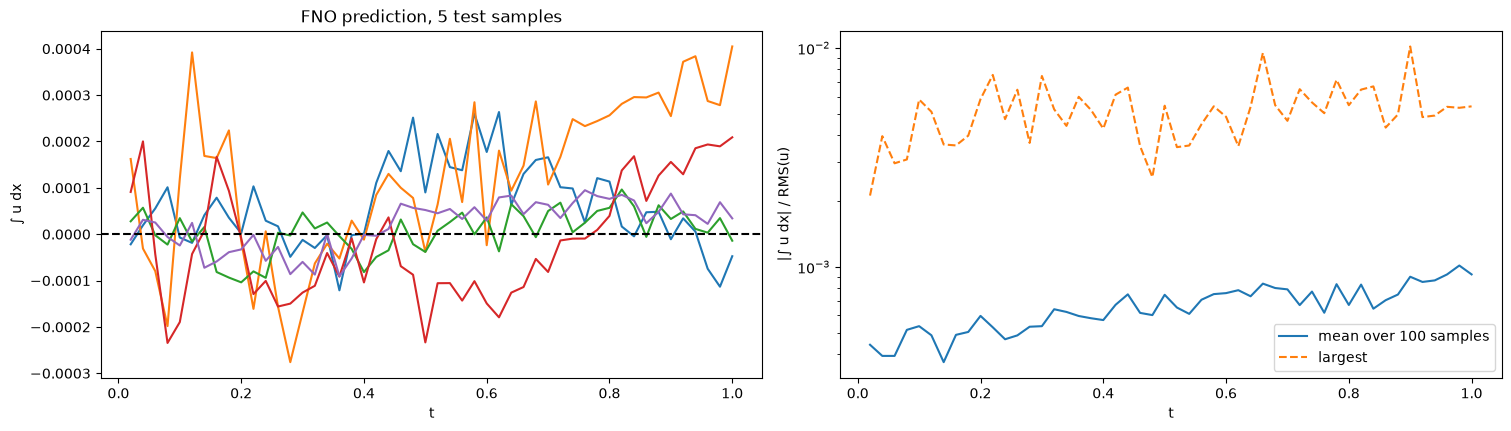

In [2]:
class SpectralConv1d(nn.Module):
    def __init__(self, ci, co, modes):
        super().__init__()
        self.modes = modes
        self.w = nn.Parameter(torch.randn(ci, co, modes, dtype=torch.cfloat) / (ci * co))
    def forward(self, v):
        N = v.shape[-1]; vh = torch.fft.rfft(v)
        out = torch.zeros(v.shape[0], self.w.shape[1], N // 2 + 1, dtype=torch.cfloat)
        m = min(self.modes, N // 2 + 1)
        out[:, :, :m] = torch.einsum("bik,iok->bok", vh[:, :, :m], self.w[:, :, :m])
        return torch.fft.irfft(out, n=N)

class FNO1d(nn.Module):
    def __init__(self, modes=16, width=64, layers=4, cin=2, cout=50):
        super().__init__()
        self.P = nn.Conv1d(cin, width, 1)
        self.K = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(layers)])
        self.W = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(layers)])
        self.Q1, self.Q2 = nn.Conv1d(width, 128, 1), nn.Conv1d(128, cout, 1)
    def forward(self, a):
        v = self.P(a)
        for i, (K, W) in enumerate(zip(self.K, self.W)):
            v = K(v) + W(v)
            if i < len(self.K) - 1: v = F.gelu(v)
        return self.Q2(F.gelu(self.Q1(v)))

test = np.load(D12 + "burgers_test_1024.npz")["u"].astype(np.float32)        # [100, 51, 1024]
fno = FNO1d(); fno.load_state_dict(torch.load(D12 + "fno_k16.pt", map_location="cpu")); fno.eval()
u0 = torch.tensor(test[:, 0]); xN = torch.arange(1024) / 1024
with torch.no_grad():
    pred = fno(torch.stack([u0, xN.expand_as(u0)], 1)).numpy()               # [100, 50, 1024]

T = 0.02 * np.arange(1, 51)
total = pred.mean(-1)                                  # integral of u over [0, 1) on a uniform grid
rms = np.sqrt((test[:, 1:] ** 2).mean(-1))
print(f"reference: largest |total| over all samples and times = {np.abs(test.astype(np.float64).mean(-1)).max():.1e} (float16 storage)")
print(f"FNO:       mean |total| / RMS(u) = {(np.abs(total) / rms).mean():.1e},  largest = {(np.abs(total) / rms).max():.1e}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
for i in [0, 3, 7, 11, 20]:
    ax[0].plot(T, total[i])
ax[0].axhline(0, color="k", ls="--"); ax[0].set(xlabel="t", ylabel="∫ u dx", title="FNO prediction, 5 test samples")
ax[1].semilogy(T, (np.abs(total) / rms).mean(0), label="mean over 100 samples")
ax[1].semilogy(T, (np.abs(total) / rms).max(0), "--", label="largest")
ax[1].set(xlabel="t", ylabel="|∫ u dx| / RMS(u)"); ax[1].legend()
plt.show()

**What to observe**

* The exact total is 0 at all times. The FNO total is of order $10^{-4}$: below $10^{-3}$ of the size of $u$ on average and up to $10^{-2}$ for the worst sample.
* The relative violation grows with $t$: the solution decays, while the error in the total does not.
* Nothing in the FNO makes the total zero. The model learned it approximately from the data.

---
## Part 2: Exact boundary and initial conditions

The Lecture 14 problem: $u_t + u u_x = \nu u_{xx}$ on $x \in [-1, 1]$, $t \in [0, 1]$, $\nu = 0.01/\pi$, $u(x, 0) = -\sin(\pi x)$, $u(\pm 1, t) = 0$.

* **Soft**: the network output is $u_\theta = N_\theta(x, t)$. Loss = residual + initial-condition error + boundary error (Lecture 14).
* **Hard**: $u_\theta(x, t) = -\sin(\pi x) + t\,(1 - x^2)\,N_\theta(x, t)$. At $t = 0$ and at $x = \pm 1$ the second term is zero, so the conditions hold for any weights. Loss = residual only.

Both: 8 hidden layers of 20 tanh neurons, 4000 collocation points, Adam ($10^{-3} \to 10^{-4}$, 10000 iterations), then L-BFGS (up to 5000 iterations), float64. The reference is the exact Cole-Hopf solution on a 256 × 101 grid.

In [3]:
torch.set_default_dtype(torch.float64)
NU_P = 0.01 / np.pi

class PINN(nn.Module):
    def __init__(self, width=20, depth=8, hard=False):
        super().__init__()
        self.hidden = nn.ModuleList([nn.Linear(2, width)] + [nn.Linear(width, width) for _ in range(depth - 1)])
        self.out = nn.Linear(width, 1); self.hard = hard
    def forward(self, x, t):
        h = torch.cat([x, 2 * t - 1], 1)
        for l in self.hidden: h = torch.tanh(l(h))
        N = self.out(h)
        if self.hard:   # u = u0(x) + t (1 - x^2) N(x, t)
            return -torch.sin(np.pi * x) + t * (1 - x**2) * N
        return N

def load_pinn(name):
    ck = torch.load(D15 + name + ".pt", weights_only=False)
    m = PINN(hard=ck["hard"]); m.load_state_dict(ck["state_dict"]); return m.eval()

xg, tg = np.linspace(-1, 1, 256), np.linspace(0, 1, 101); X, Tt = np.meshgrid(xg, tg)   # rows: time
ref = np.load(D15 + "burgers_pinn_ref.npy")
hist = json.load(open(D15 + "pinn_history.json"))
P = {}
for name in ["soft", "hard"]:
    m = load_pinn("pinn_" + name)
    with torch.no_grad():
        P[name] = m(torch.tensor(X.reshape(-1, 1)), torch.tensor(Tt.reshape(-1, 1))).numpy().reshape(Tt.shape)
    e = np.linalg.norm(P[name] - ref) / np.linalg.norm(ref)
    print(f"{name}: relative L2 error {e:.1e},  max |u(±1, t)| = {np.abs(P[name][:, [0, -1]]).max():.1e},  "
          f"max |u(x, 0) - u0| = {np.abs(P[name][0] - ref[0]).max():.1e}")

soft: relative L2 error 2.7e-03,  max |u(±1, t)| = 3.1e-04,  max |u(x, 0) - u0| = 8.3e-04
hard: relative L2 error 6.1e-02,  max |u(±1, t)| = 1.2e-16,  max |u(x, 0) - u0| = 5.6e-17


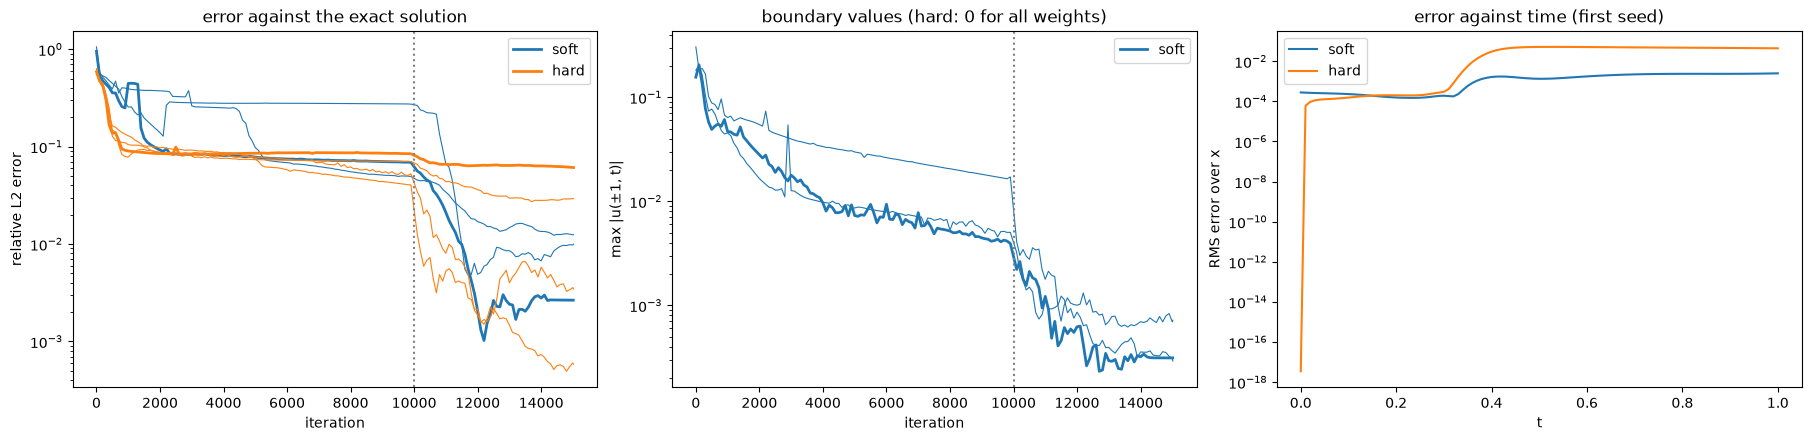

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3), layout="constrained")
for name, c in [("soft", "C0"), ("hard", "C1")]:
    for k, h in enumerate(hist[name]):
        ax[0].semilogy(h["it"], h["err"], color=c, lw=2 if k == 0 else 0.8, label=name if k == 0 else None)
        if name == "soft":
            ax[1].semilogy(h["it"], h["bcerr"], color=c, lw=2 if k == 0 else 0.8, label="soft" if k == 0 else None)
ax[0].axvline(hist["soft"][0]["adam"], color="gray", ls=":"); ax[1].axvline(hist["soft"][0]["adam"], color="gray", ls=":")
ax[0].set(xlabel="iteration", ylabel="relative L2 error", title="error against the exact solution"); ax[0].legend()
ax[1].set(xlabel="iteration", ylabel="max |u(±1, t)|", title="boundary values (hard: 0 for all weights)"); ax[1].legend()
for name, c in [("soft", "C0"), ("hard", "C1")]:
    ax[2].semilogy(tg, np.sqrt(((P[name] - ref) ** 2).mean(1)), color=c, label=name)
ax[2].set(xlabel="t", ylabel="RMS error over x", title="error against time (first seed)"); ax[2].legend()
plt.show()

**What to observe**

* The hard model's boundary values and initial condition are exact (zero up to round-off) from the first iteration. The soft model's boundary values are small, and they stop improving once L-BFGS converges.
* Thin lines are other random seeds. The errors of both models fall mainly during L-BFGS, after the dotted line. The final error varies more across seeds than between soft and hard.
* The error after training is dominated by the shock at $x = 0$ (largest after $t \approx 0.3$), for both models. Exact conditions do not make the residual easier to minimize, and a small shift of the shock gives a large $L^2$ error.

---
## Part 3: Conservation on a coarse grid

We average the Lecture 12 Burgers data ($\nu = 0.01$, periodic $[0, 1)$) onto **32 cells** and learn one step of $\Delta t = 0.02$. A rollout applies the step 50 times, to $t = 1$. Three models with the same periodic 1D CNN $N_\theta$ (6 layers, 64 channels, kernel 5):

* **Direct**: $u^{n+1} = u^n + N_\theta(u^n)$.
* **Projected**: the direct model, followed after each step by $u_i \leftarrow u_i - \frac{1}{N}\sum_j (u_j - u_j^0)$, the projection onto the initial total.
* **Flux form**: the CNN output is the face flux $F_{i+1/2}$, and $u_i^{n+1} = u_i^n - (F_{i+1/2} - F_{i-1/2})$ (the factor $\Delta t/\Delta x$ is absorbed in $F$). The sum over cells telescopes, so the total is conserved for any weights.

All were trained one step, MSE, Adam ($10^{-3}$, cosine), 6000 iterations of batch 128.

In [5]:
torch.set_default_dtype(torch.float32)
NU, DT, NC, SUB = 0.01, 0.02, 32, 10

def coarsen(u, N=NC):
    # cell averages on N cells
    return u.reshape(*u.shape[:-1], N, u.shape[-1] // N).mean(-1)

def solver_step(u, nu=NU, dt=DT, sub=SUB):
    # finite-volume Burgers on N periodic cells: Rusanov flux for u^2/2, central viscous flux, SSP-RK2, `sub` substeps
    N = u.shape[-1]; dx = 1.0 / N; h = dt / sub
    def rhs(u):
        ur = torch.roll(u, -1, -1)                                         # u_{i+1}
        a = torch.maximum(u.abs(), ur.abs())
        Fc = 0.25 * (u**2 + ur**2) - 0.5 * a * (ur - u) - nu * (ur - u) / dx   # flux at face i+1/2
        return -(Fc - torch.roll(Fc, 1, -1)) / dx
    for _ in range(sub):
        u1 = u + h * rhs(u)
        u = 0.5 * (u + u1 + h * rhs(u1))
    return u

class Net(nn.Module):
    def __init__(self, width=64, layers=6, k=5):
        super().__init__()
        conv = lambda i, o: nn.Conv1d(i, o, k, padding=k // 2, padding_mode="circular")
        L = [conv(1, width), nn.GELU()]
        for _ in range(layers - 2): L += [conv(width, width), nn.GELU()]
        self.net = nn.Sequential(*L, conv(width, 1))
    def forward(self, u): return self.net(u[:, None])[:, 0]

def div(Fc): return Fc - torch.roll(Fc, 1, -1)          # F_{i+1/2} - F_{i-1/2}

class Direct(nn.Module):          # u_{n+1} = u_n + N(u_n)
    def __init__(s): super().__init__(); s.f = Net()
    def forward(s, u): return u + s.f(u)
class FluxForm(nn.Module):        # u_{n+1} = u_n - (F_{i+1/2} - F_{i-1/2})
    def __init__(s): super().__init__(); s.f = Net()
    def forward(s, u): return u - div(s.f(u))
class Hybrid(nn.Module):          # u_{n+1} = S(u_n) - (G_{i+1/2} - G_{i-1/2}),  G = N(S(u_n))
    def __init__(s, nu=NU): super().__init__(); s.f = Net(); s.nu = nu
    def forward(s, u):
        v = solver_step(u, nu=s.nu); return v - div(s.f(v))
class Solver(nn.Module):
    def __init__(s, nu=NU): super().__init__(); s.nu = nu
    def forward(s, u): return solver_step(u, nu=s.nu)

def load(model, name):
    model.load_state_dict(torch.load(D15 + name + ".pt", map_location="cpu")); return model.eval()

@torch.no_grad()
def rollout(step, u0, n=50, project=False):
    us = [u0]; u = u0
    for _ in range(n):
        u = step(u)
        if project: u = u - u.mean(-1, keepdim=True) + u0.mean(-1, keepdim=True)
        us.append(u)
    return torch.stack(us, 1).numpy()

def rel_err(r, ref):   # relative L2 error at each time, averaged over samples
    return (np.linalg.norm(r - ref, axis=2) / np.linalg.norm(ref, axis=2)).mean(0)

refs = np.load(D15 + "burgers_coarse_refs.npz")       # 32-cell references: 'test', 'x2', 'nu0.005', 'nu0.02'
ref = coarsen(test.astype(np.float32))                 # [100, 51, 32]
ref2 = refs["x2"]                                      # initial conditions multiplied by 2
models = {"direct": (load(Direct(), "direct"), False), "projected": (load(Direct(), "direct"), True),
          "flux form": (load(FluxForm(), "flux"), False)}
t = DT * np.arange(51)

direct     test: error at t = 1: 1.5e-03, change in total / RMS(u): 1.7e-04   x2: error at t = 1: 5.3e-03
projected  test: error at t = 1: 1.2e-03, change in total / RMS(u): 8.0e-09   x2: error at t = 1: 1.9e-03
flux form  test: error at t = 1: 1.0e-03, change in total / RMS(u): 2.6e-08   x2: error at t = 1: 1.6e-03


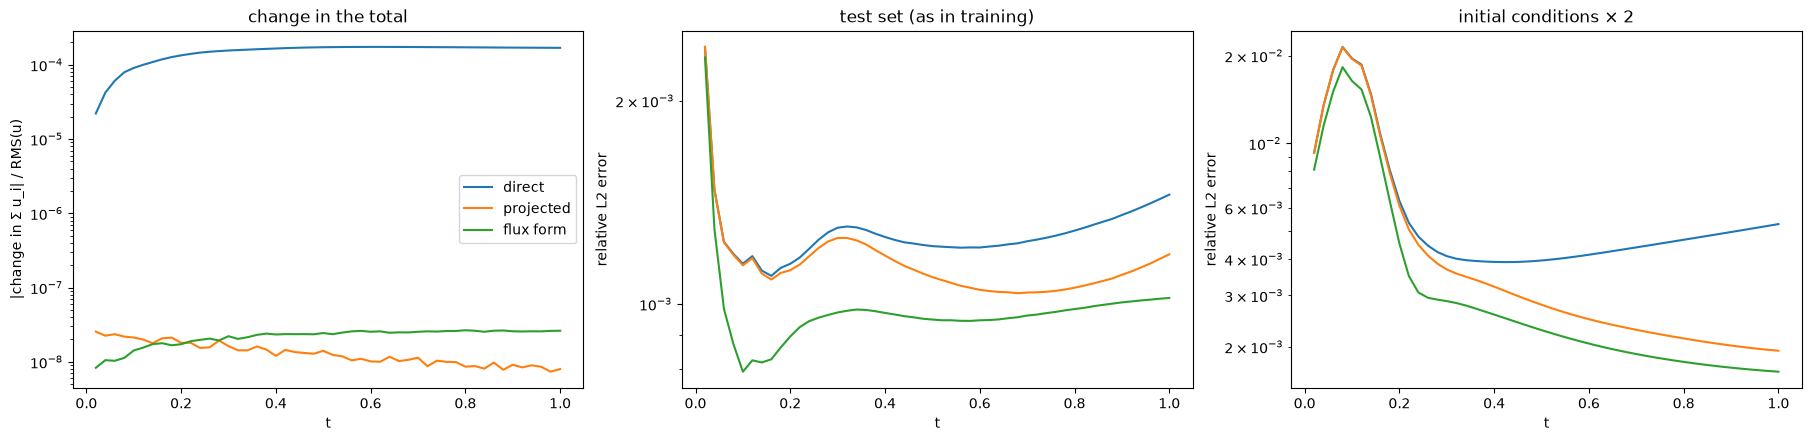

flux form  test: error at t = 1: 1.0e-03, change in total / RMS(u): 2.5e-08   

x2: error at t = 1: 1.6e-03


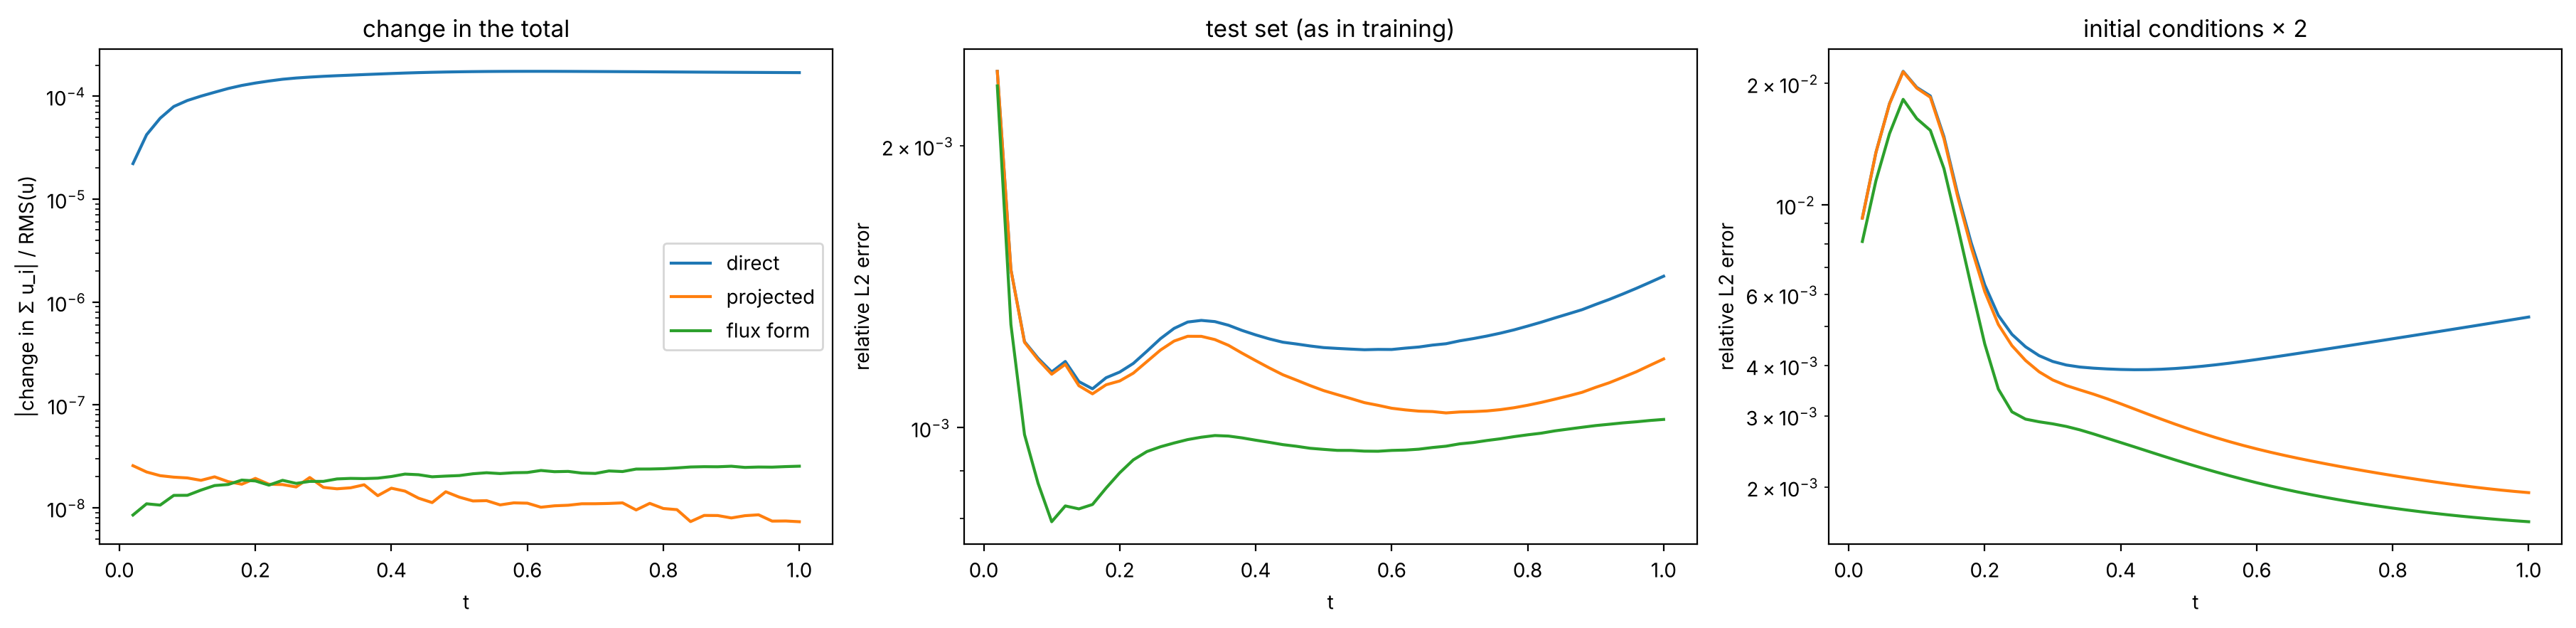

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3), layout="constrained")
for name, (m, proj) in models.items():
    for a, R in [(ax[1], ref), (ax[2], ref2)]:
        r = rollout(m, torch.tensor(R[:, 0]), project=proj)
        a.semilogy(t[1:], rel_err(r, R)[1:], label=name)
        if R is ref:
            change = np.abs(r.mean(-1) - r[:, :1].mean(-1)).mean(0) / np.sqrt((R**2).mean())
            ax[0].semilogy(t[1:], np.maximum(change[1:], 1e-10), label=name)
            print(f"{name:10s} test: error at t = 1: {rel_err(r, R)[-1]:.1e}, change in total / RMS(u): {change[-1]:.1e}", end="   ")
        else:
            print(f"x2: error at t = 1: {rel_err(r, R)[-1]:.1e}")
ax[0].set(xlabel="t", ylabel="|change in Σ u_i| / RMS(u)", title="change in the total"); ax[0].legend()
ax[1].set(xlabel="t", ylabel="relative L2 error", title="test set (as in training)")
ax[2].set(xlabel="t", ylabel="relative L2 error", title="initial conditions × 2")
plt.show()

**What to observe**

* The direct model changes the total by about $10^{-4}$ of the size of $u$. The projected and flux-form models conserve it to float32 round-off ($\sim 10^{-8}$).
* On the test set, the three models have similar errors, around $10^{-3}$: conservation is learnt reasonably well from data.
* With initial conditions twice as large, outside the training data, all errors are larger. Late in the rollout the conservative models have lower error than the direct model.
* These are single training runs. The size of the differences varies with the seed, the trend agrees with the literature (Hansen et al. 2023).

---
## Part 4: Hybrid models

The finite-volume solver above is first order (Rusanov flux) on 32 cells. Its numerical diffusion is larger than $\nu = 0.01$, so it smears the fronts. A hybrid takes one solver step and adds a learned correction in flux form (so the total stays exact):

$$u^{n+1} = \mathcal S(u^n) - \big(G_{i+1/2} - G_{i-1/2}\big), \qquad G = N_\theta(\mathcal S(u^n)).$$

* **Hybrid, one step** (a priori): trained on single steps from reference states.
* **Hybrid, through the solver** (a posteriori): trained on 4-step rollouts, backpropagating through the solver (Lecture 7: unrolled training).

Same CNN and optimizer as in Part 3.

coarse solver            error at t = 0.2: 1.1e-01   t = 1: 1.0e-01
direct (pure ML)         error at t = 0.2: 1.1e-03   t = 1: 1.5e-03
hybrid, one step         error at t = 0.2: 3.0e-03   t = 1: 4.9e-03
hybrid, through solver   error at t = 0.2: 3.0e-03   t = 1: 4.9e-03


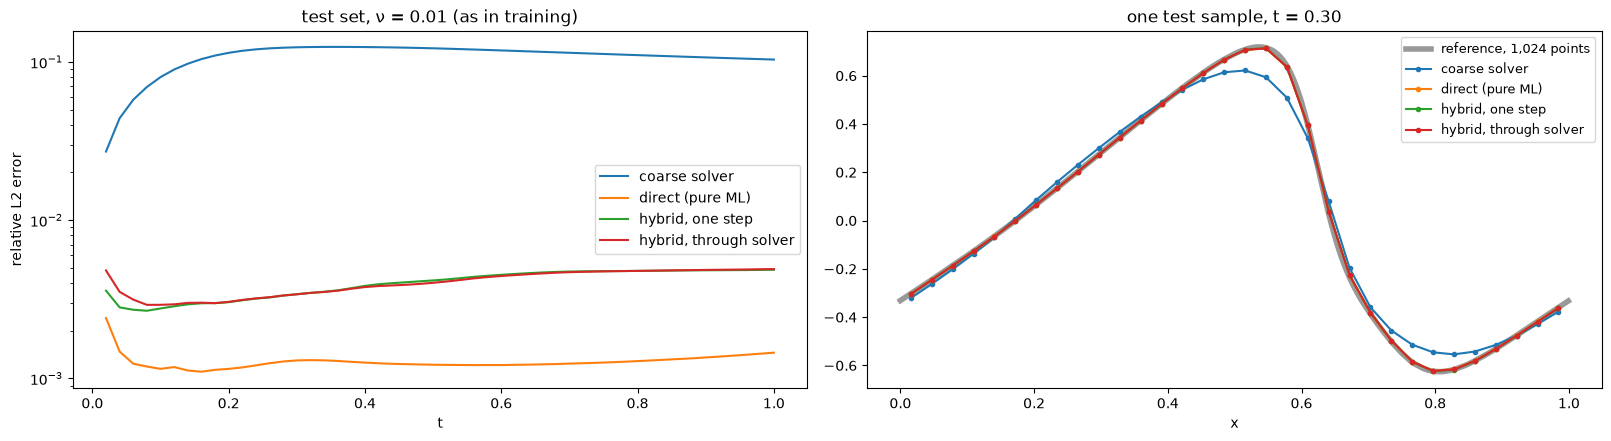

In [7]:
H = {"coarse solver": Solver(), "direct (pure ML)": models["direct"][0],
     "hybrid, one step": load(Hybrid(), "hybrid1"), "hybrid, through solver": load(Hybrid(), "hybrid4")}
R_test = {name: rollout(m, torch.tensor(ref[:, 0])) for name, m in H.items()}
fig, ax = plt.subplots(1, 2, figsize=(16, 4.3), layout="constrained")
for name, r in R_test.items():
    ax[0].semilogy(t[1:], rel_err(r, ref)[1:], label=name)
    print(f"{name:24s} error at t = 0.2: {rel_err(r, ref)[10]:.1e}   t = 1: {rel_err(r, ref)[-1]:.1e}")
ax[0].set(xlabel="t", ylabel="relative L2 error", title="test set, ν = 0.01 (as in training)"); ax[0].legend()
i, j = 3, 15
xc = (np.arange(NC) + 0.5) / NC
ax[1].plot(np.arange(1024) / 1024, test[i, j], color="0.6", lw=4, label="reference, 1,024 points")
for name, r in R_test.items():
    ax[1].plot(xc, r[i, j], "-o", ms=3, label=name)
ax[1].set(xlabel="x", title=f"one test sample, t = {t[j]:.2f}"); ax[1].legend(fontsize=9)
plt.show()

**What to observe**

* The coarse solver alone has an error of about 10%: it smears the fronts.
* Both hybrids reduce that error by more than an order of magnitude.
* On data like the training data, the pure network is the most accurate. A network that sees the reference state can learn the entire step while the hybrid has to learn the part the solver gets wrong, which here includes all of its numerical diffusion.
* The two hybrids have the same error: the one-step hybrid is already stable over 50 steps, so training through the solver adds little here. It matters when one-step models drift (Um et al. 2020; Frezat et al. 2022).

---
## Part 5: A viscosity outside the training data

All models were trained at $\nu = 0.01$. We now test at $\nu = 0.005$ (sharper fronts) and $\nu = 0.02$. The solver inside the hybrid uses the new $\nu$. The networks are unchanged. The direct network has no input for $\nu$.

nu = 0.005
   coarse solver            error at t = 1: 1.4e-01
   direct (pure ML)         error at t = 1: 1.9e-01
   hybrid, one step         error at t = 1: 1.7e-02
   hybrid, through solver   error at t = 1: 1.8e-02
nu = 0.02
   coarse solver            error at t = 1: 7.1e-02
   direct (pure ML)         error at t = 1: 4.0e-01
   hybrid, one step         error at t = 1: 4.5e-03
   hybrid, through solver   error at t = 1: 4.3e-03


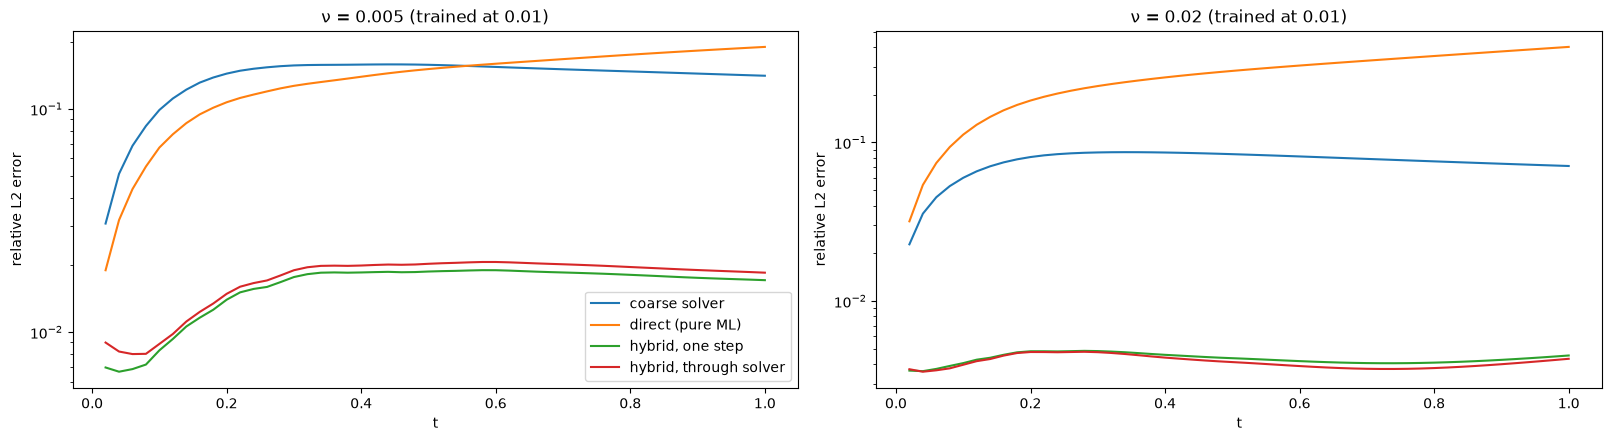

   direct (pure ML)         error at t = 1: 4.0e-01


   hybrid, one step         error at t = 1: 4.5e-03


   hybrid, through solver   error at t = 1: 4.3e-03


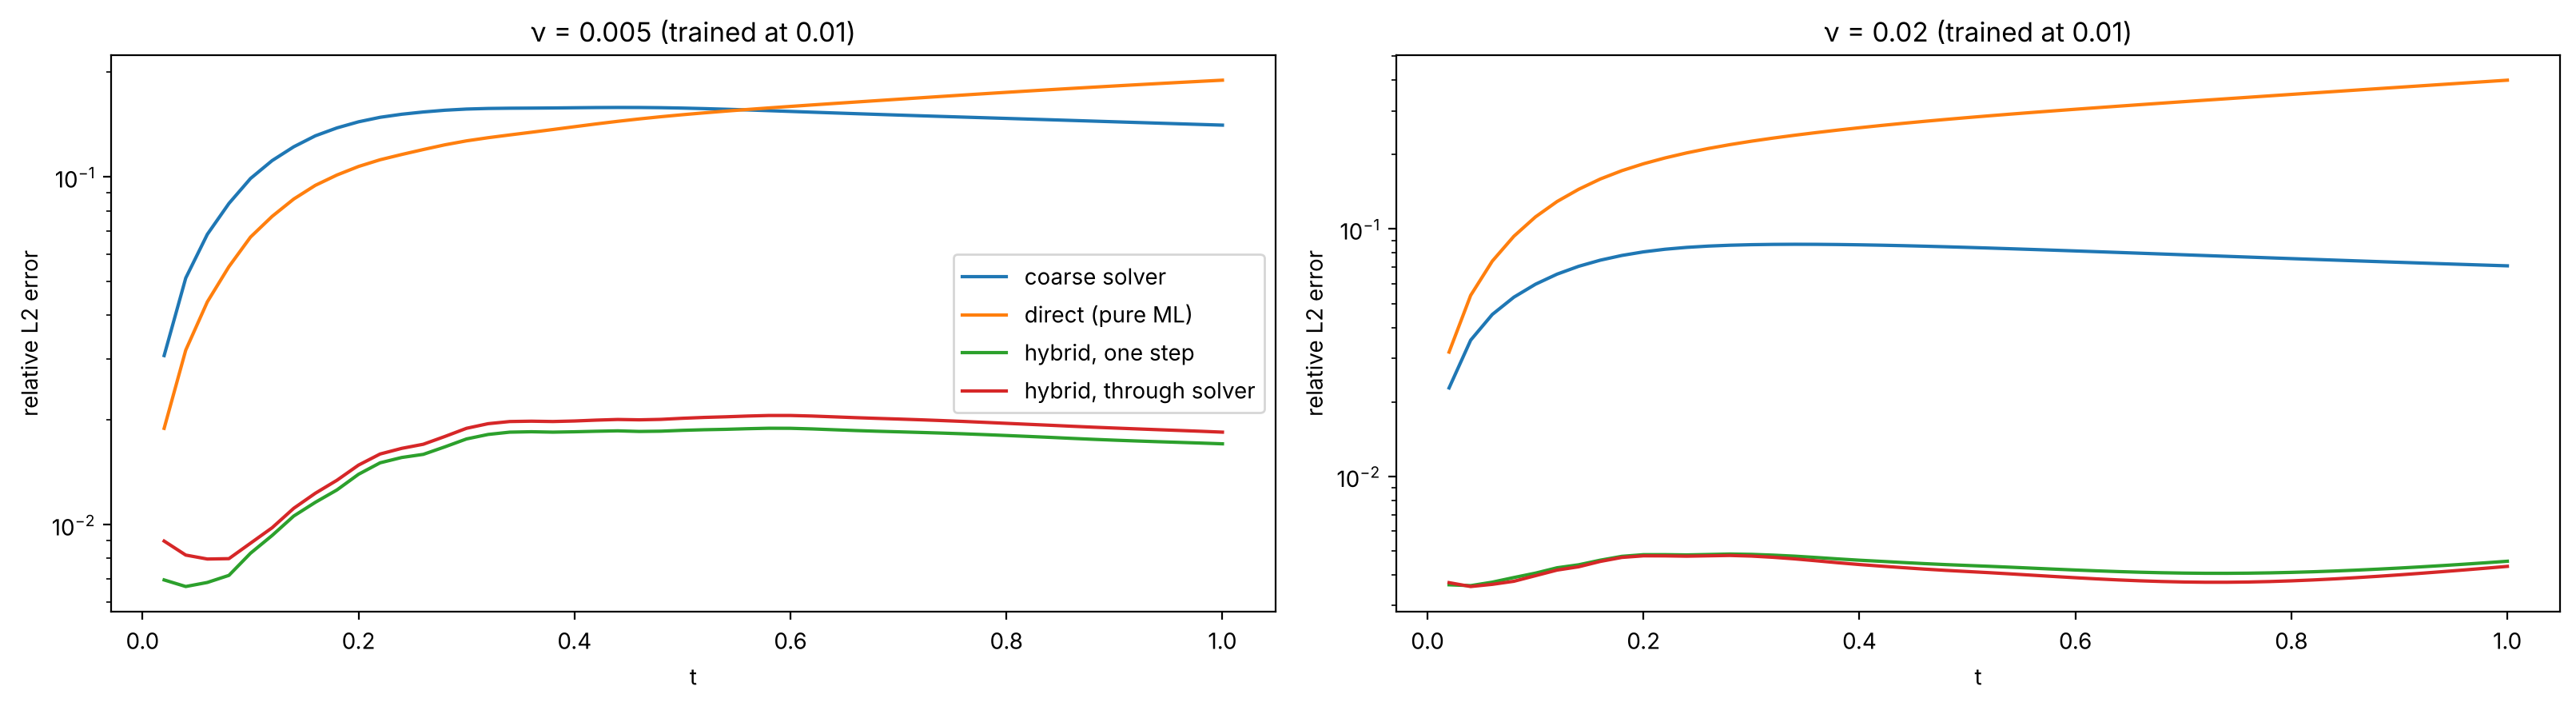

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.3), layout="constrained")
for a, nu in zip(ax, [0.005, 0.02]):
    R = refs[f"nu{nu:g}"]
    Hn = {"coarse solver": Solver(nu), "direct (pure ML)": models["direct"][0],
          "hybrid, one step": load(Hybrid(nu), "hybrid1"), "hybrid, through solver": load(Hybrid(nu), "hybrid4")}
    print(f"nu = {nu}")
    for name, m in Hn.items():
        r = rollout(m, torch.tensor(R[:, 0]))
        a.semilogy(t[1:], rel_err(r, R)[1:], label=name)
        print(f"   {name:24s} error at t = 1: {rel_err(r, R)[-1]:.1e}")
    a.set(xlabel="t", ylabel="relative L2 error", title=f"ν = {nu} (trained at 0.01)")
ax[0].legend(); plt.show()

**What to observe**

* The direct network continues to produce $\nu = 0.01$ dynamics, so its error grows to tens of percent at both viscosities.
* The hybrids get the new viscosity from the solver and their error stays near the in-distribution level.
* This comparison highlights the advantage of hybrids: the known physics, including its parameters, lives in the solver. A pure network would need $\nu$ as an input and training data at several values of $\nu$.

---
## Exercises

1. **Where to project.** Replace the uniform projection in Part 3 by a weighted one, $u_i \leftarrow u_i - w_i \sum_j (u_j - u_j^0)/\sum_j w_j$, with $w_i = |u_{i+1} - u_{i-1}|$ (larger near fronts). Does the error with initial conditions × 2 change? Relate the result to ProbConserv (Hansen et al. 2023).
2. **Unroll length.** Train the hybrid with $m$ = 1, 2, 4 and 8 unrolled steps (`train_step_model("hybrid", m)`). Plot the error at $t = 1$ against $m$ for $\nu$ = 0.01 and 0.005, and the training time.
3. **Viscosity as an input.** Generate data at $\nu$ = 0.005, 0.01 and 0.02 with `burgers_reference`, add $\nu$ as a second input channel to the direct network, and compare it with the hybrid at $\nu$ = 0.0075 and 0.015.
4. **A divergence-free field.** Write a network $\psi_\theta(x, y)$, compute $u = \partial\psi_\theta/\partial y$, $v = -\partial\psi_\theta/\partial x$ with autograd, and verify that the divergence is zero to round-off on random points. Compare with a network that outputs $(u, v)$ directly.

In [9]:
# Training code (used for the checkpoints; run offline, e.g. on one HPC3 GPU)

def burgers_reference(u0, nu=0.01, nsteps=50, dt_save=0.02, dt=1e-4):
    # pseudo-spectral Burgers on len(u0) periodic points, 2/3 dealiasing, integrating-factor RK4; u0: [B, N] float64
    N = u0.shape[-1]; k = 2 * np.pi * torch.fft.rfftfreq(N, 1 / N).double()
    mask = (torch.arange(N // 2 + 1) < N // 3).double(); E = torch.exp(-nu * k**2 * dt / 2); E2 = E**2
    def Nl(vh):
        u = torch.fft.irfft(vh * mask, n=N); return -0.5j * k * torch.fft.rfft(u * u) * mask
    vh = torch.fft.rfft(torch.as_tensor(u0, dtype=torch.float64)); out = [torch.fft.irfft(vh, n=N)]
    for s in range(nsteps):
        for _ in range(int(round(dt_save / dt))):
            a = Nl(vh); b = Nl(E * (vh + dt / 2 * a)); c = Nl(E * vh + dt / 2 * b); d = Nl(E2 * vh + dt * E * c)
            vh = E2 * vh + dt / 6 * (E2 * a + 2 * E * (b + c) + d)
        out.append(torch.fft.irfft(vh, n=N))
    return torch.stack(out, 1).numpy()

def train_step_model(kind, m=1, iters=6000, seed=0):
    # kind: "direct", "flux" or "hybrid"; m: number of steps unrolled in the loss (m = 1: one-step training)
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    U = torch.tensor(coarsen(np.load(D12 + "burgers_train_128.npz")["u"].astype(np.float32)))   # [1000, 51, 32]
    model = {"direct": Direct, "flux": FluxForm, "hybrid": Hybrid}[kind]()
    opt = torch.optim.Adam(model.parameters(), 1e-3); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters)
    for it in range(iters):
        i = torch.as_tensor(rng.integers(0, len(U), 128)); j = torch.as_tensor(rng.integers(0, U.shape[1] - m, 128))
        u = U[i, j]; loss = 0
        for s in range(1, m + 1):                 # unrolled through the model (and the solver, for the hybrid)
            u = model(u); loss = loss + ((u - U[i, j + s]) ** 2).mean() / m
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model

def train_pinn(hard, adam=10000, lbfgs=5000, seed=0):
    torch.set_default_dtype(torch.float64); torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = PINN(hard=hard)
    for l in list(net.hidden) + [net.out]: nn.init.xavier_normal_(l.weight); nn.init.zeros_(l.bias)
    D = lambda f, v: torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]
    col = lambda a: torch.tensor(np.asarray(a, float)).reshape(-1, 1)
    xf = col(rng.uniform(-1, 1, 4000)).requires_grad_(True); tf = col(rng.uniform(0, 1, 4000)).requires_grad_(True)
    xi = col(np.linspace(-1, 1, 256)); ti = torch.zeros_like(xi); tb = col(np.linspace(0, 1, 256))
    def loss():
        u = net(xf, tf); ut, ux = D(u, tf), D(u, xf)
        L = ((ut + u * ux - NU_P * D(ux, xf)) ** 2).mean()
        if not hard:
            L = L + ((net(xi, ti) + torch.sin(np.pi * xi)) ** 2).mean()
            L = L + (net(torch.full_like(tb, -1.0), tb) ** 2).mean() + (net(torch.full_like(tb, 1.0), tb) ** 2).mean()
        return L
    opt = torch.optim.Adam(net.parameters(), 1e-3); sched = torch.optim.lr_scheduler.ExponentialLR(opt, 0.1 ** (1 / adam))
    for it in range(adam):
        opt.zero_grad(); L = loss(); L.backward(); opt.step(); sched.step()
    lb = torch.optim.LBFGS(net.parameters(), lr=1.0, max_iter=20, history_size=50, line_search_fn="strong_wolfe",
                           tolerance_grad=1e-12, tolerance_change=1e-14)
    def closure():
        lb.zero_grad(); L = loss(); L.backward(); return L
    for _ in range(lbfgs // 20):
        lb.step(closure)
    return net

# Examples:
# hybrid4 = train_step_model("hybrid", m=4)      # about 30 minutes on a CPU, a few minutes on a GPU
# pinn_hard = train_pinn(hard=True)               # about 20 minutes on a CPU